# Tugas Praktikum - HDBSCAN pada Dataset Iris

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js05-klasterisasi-hierarki/tugas)

## Deskripsi Tugas

Gunakan dataset nyata dari sklearn.datasets, lakukan HDBSCAN, laporkan jumlah klaster/noise, visualisasikan, lalu bandingkan dengan label asli. Dataset yang dipilih adalah Iris.

## Langkah 0 - Persiapan Lingkungan

In [1]:
import sys
import numpy as np
np.random.seed(42)
print("Kernel:", sys.executable)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Memuat dan Menyiapkan Dataset

In [2]:
import hdbscan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

iris = load_iris(as_frame=True)
X = iris.data
y_true = iris.target
X_scaled = StandardScaler().fit_transform(X)
display(X.head())
print('Jumlah data dan fitur:', X.shape)
print('Label asli:', dict(enumerate(iris.target_names)))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Jumlah data dan fitur: (150, 4)
Label asli: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


## Langkah 2 - Clustering dengan HDBSCAN

In [3]:
model = hdbscan.HDBSCAN(min_cluster_size=5, min_samples=5)
labels = model.fit_predict(X_scaled)
noise_mask = labels == -1
n_clusters = len(set(labels)) - int(noise_mask.any())
summary = pd.DataFrame([{
    'Jumlah klaster': n_clusters, 'Noise': int(noise_mask.sum()),
    'Noise (%)': 100 * noise_mask.mean(),
    'ARI (semua baris)': adjusted_rand_score(y_true, labels),
    'NMI (semua baris)': normalized_mutual_info_score(y_true, labels),
}])
display(summary.round(4))
display(pd.Series(labels, name='Cluster').value_counts().sort_index().to_frame('Jumlah data'))


,Jumlah klaster,Noise,Noise (%),ARI (semua baris),NMI (semua baris)
0,2,2,1.3333,0.5638,0.7175


,Jumlah data
Cluster,
-1,2
0,50
1,98


## Langkah 3 - Visualisasi PCA dan Label Asli

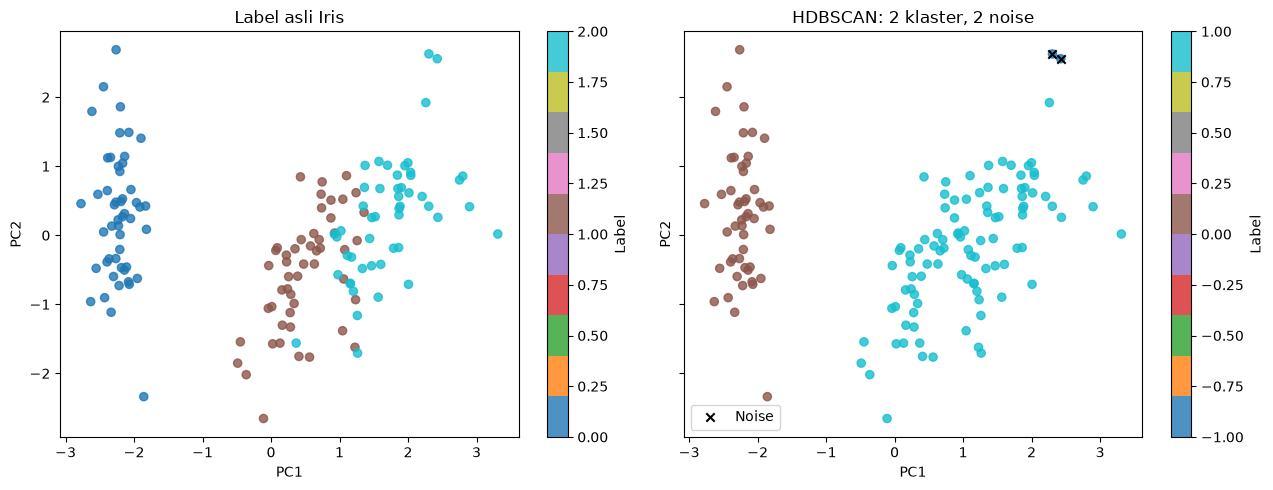

Variansi yang dijelaskan PC1 + PC2: 95.81%


In [4]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, values, heading in [(axes[0], y_true, 'Label asli Iris'),
                           (axes[1], labels, f'HDBSCAN: {n_clusters} klaster, {noise_mask.sum()} noise')]:
    points = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=values, cmap='tab10', s=35, alpha=0.8)
    if ax is axes[1] and noise_mask.any():
        ax.scatter(X_2d[noise_mask, 0], X_2d[noise_mask, 1], c='black', marker='x', label='Noise')
        ax.legend()
    ax.set(title=heading, xlabel='PC1', ylabel='PC2')
    fig.colorbar(points, ax=ax, label='Label')
plt.tight_layout()
plt.show()
print(f'Variansi yang dijelaskan PC1 + PC2: {pca.explained_variance_ratio_.sum():.2%}')


## Langkah 4 - Membandingkan Hasil dengan Label Asli

In [5]:
comparison = pd.crosstab(pd.Series(labels, name='Cluster HDBSCAN'),
                         pd.Series(iris.target_names[y_true], name='Spesies asli'))
display(comparison)
if 2 <= len(np.unique(labels[~noise_mask])) < (~noise_mask).sum():
    print('Silhouette (tanpa noise):', round(silhouette_score(X_scaled[~noise_mask], labels[~noise_mask]), 4))
print('Label cluster adalah ID arbitrer; cluster 0 tidak otomatis sama dengan target 0.')
print('Proporsi baris yang mendapat klaster:', f'{(~noise_mask).mean():.2%}')


Spesies asli,setosa,versicolor,virginica
Cluster HDBSCAN,,,
-1,0,0,2
0,50,0,0
1,0,50,48


Silhouette (tanpa noise): 0.5899
Label cluster adalah ID arbitrer; cluster 0 tidak otomatis sama dengan target 0.
Proporsi baris yang mendapat klaster: 98.67%


## Analisis

Hasil belum sama sepenuhnya dengan tiga label asli Iris: HDBSCAN membentuk
**dua klaster** dan menandai **dua baris virginica sebagai noise**.
Klaster 0 berisi seluruh 50 setosa. Klaster 1 menggabungkan 50 versicolor
dan 48 virginica. Jadi setosa terpisah jelas, sedangkan dua spesies lain
belum terpisah pada parameter dan preprocessing ini.

ARI sebesar 0,5638 dan NMI sebesar 0,7175 menunjukkan kesesuaian parsial.
Label spesies tidak masuk ke fitur clustering; nomor klaster adalah ID
arbitrer. Visualisasi PCA membantu melihat pemisahan, tetapi clustering
menggunakan seluruh empat fitur hasil StandardScaler.